# 2.2 Model interrogation

In this example, we invert the data produced in Example 2.1 and then use the posterior pdf to test for a hypothesis concerning the relationship between two parameters.

In [31]:
#__ Import: Numerical __
import numpy as np

#__ Import: Topophone2 __
from topophone2.topophone import decompose
from topophone2.utils.read import read_txt
from topophone2.utils.math import density_params

#__ Import: Plotting __
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

In [ ]:
#__ Set up: Plotting __
theme = ['#DC4424', '#74A466', '#24448C', '#F8BC5C']
small, large = 8, 10
plt.rcParams["font.sans-serif"] = ['Arial']

#__ Set up: Random seed __
np.random.seed(2026)

#__ Disable: Warnings __
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

### 2.2.1 Load example data

First, we load in the data from Example 2.1.

In [ ]:
#__ Read: Signal + noise __
out = read_txt("../data/hukkakero/signal_topophone2.txt")
freq_Hz   = out[0]  # Frequency vector          [Hz]       (frequency)
x         = out[1]  # Receiver position         [m]        (receiver, direction)
Gamma_obs = out[2]  # Sample-covariance matrix  [Pa2.Hz-1] (frequency, receiver, receiver)
N_obs     = out[3]  # Independent observations
freq      = 2 * np.pi * freq_Hz  # Angular frequency vector [rad.s-1] (frequency)

#__ Read: Noise only __
out = read_txt("../data/hukkakero/noise_topophone2.txt")
Gamma_obs_noise = out[2]  # Sample-covariance matrix  [Pa2.Hz-1] (frequency, receiver, receiver)
N_obs_noise     = out[3]  # Independent observations

### 2.2.2 Invert example data

We parameterise the wavefield using three components:
- a skew-normally distributed component (``'skewnormal'``),
- a sensor self-noise component (``'isoselfnoise'``),
- and a cylindrical-harmonic ambient-noise component (``{'sig':'noise2D', 'max_order':2}``).

The model vector contains the parameters...

| Signal component | Parameter set |
|---|---|
|``'skewnormal'`` | $\left(E, \xi_1, \xi_2, \sigma_1, \sigma_2, \rho_{12}, \alpha_1, \alpha_2\right)$ |
|``'isoselfnoise'`` | $\left(E\right)$ |
|``'noise2D'`` | $\left(E, s, a_1, a_2, b_1, b_2\right)$ |


In [ ]:
#__ Signals present __
sigs = [
    'skewnormal',                     # Skew-normal density function
    'isoselfnoise',                   # Self-noise
    {'sig':'noise2D', 'max_order':2}  # Cylindrical-harmonic noise field
]

#__ Prior bounds __
lower = np.array([                                      # Lower bound of prior pdf
    -40., -2.7e-3, 1.0e-3, 1e-6, 1e-6, -0.9, -5., -5.,  #     Skew-normal parameters [energy, xi_x, xi_y, sigma_x, sigma_y, rho_xy, alpha_x, alpha_y]
    -55.,                                               #     Self-noise parameters  [energy]
    -55., 2.2e-3, 0.1, -0.35, -0.55, -0.35              #     Noise field parameters [energy, slowness, a_1, a_2, b_1, b_2]
])
upper = np.array([                                      # Upper bound of prior pdf
    -30., -2.2e-3, 1.6e-3, 1e-3, 1e-3,  0.9,  5.,  5.,
    -45.,
    -45., 2.5e-3, 0.3, -0.15, -0.30, -0.15
])

#__ Number of flows __
N_flow = 8

#__ Inversion parameters __
learning_rate = 5e-4   # Learning rate for the optimiser
N_iterations  = 30000  # Number of iterations for optimiser
N_montecarlo  = 50     # Number of samples to estimate ELBO

#__ Number of samples to draw __
N_samples = 20000

The inversion is carried out using the ``topophone.decompose`` helper function.

In [ ]:
#__ Perform inversion __
decompose(
    Gamma_obs       = Gamma_obs,
    N_obs           = N_obs,
    Gamma_obs_noise = Gamma_obs_noise,
    N_obs_noise     = N_obs_noise,
    x               = x,
    freq            = freq,
    sigs            = sigs,
    prior_bounds    = (lower,upper),
    N_flow          = N_flow,
    learning_rate   = learning_rate,
    outpath         = "../models/hukkakero",
    N_iterations    = N_iterations,
    N_montecarlo    = N_montecarlo,
    N_out           = 6,
    N_samples       = N_samples
)

#__ Read results __
m = np.loadtxt(f"../models/hukkakero/model-samples_iteration-{N_iterations:05d}.txt")

#__ Unpack results __
w_s   = m[:,0]      # Skew-normal total energy                     (sample,)
xi    = m[:,1:3]    # Skew-normal location vector                  (sample, direction)
sigma = m[:,3:5]    # Skew-normal scale vector                     (sample, direction)
corr  = m[:,5]      # Skew-normal correlation matrix off-diagonal  (sample, direction pair)
alpha = m[:,6:8]    # Skew-normal shape vector                     (sample, direction)
w_n1  = m[:,8]      # Self-noise total energy                      (sample,)
w_n2  = m[:,9]      # Angular-harmonic total energy                (sample,)
s0    = m[:,10]     # Angular-harmonic apparent slowness           (sample,)
a     = m[:,11:13]  # Angular-harmonic cosine coefficient          (sample, order)
b     = m[:,13:15]  # Angular-harmonic sine coefficient            (sample, order)

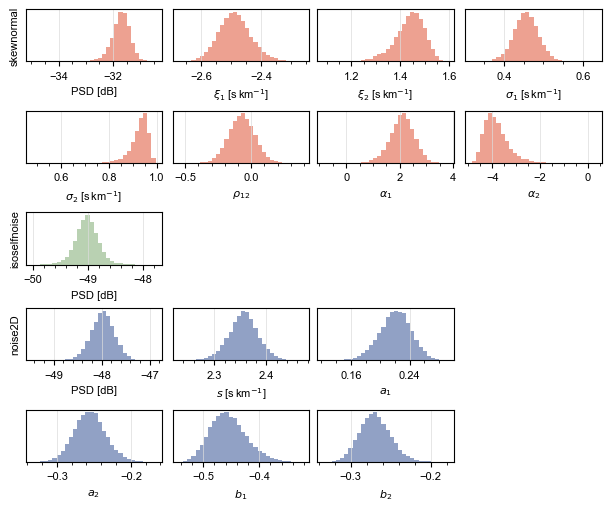

In [ ]:
#__ Create figure and axes __
fig = plt.figure(figsize=(6,5), facecolor='white', layout='constrained')
gs  = fig.add_gridspec(nrows=5, ncols=4)
axs = [
    *[fig.add_subplot(gs[0,i]) for i in range(4)],
    *[fig.add_subplot(gs[1,i]) for i in range(4)],
    fig.add_subplot(gs[2,0]),
    *[fig.add_subplot(gs[3,i]) for i in range(3)],
    *[fig.add_subplot(gs[4,i]) for i in range(3)]
]

#__ Labels __
for ax, xlab, ylab in zip(axs,
    [
        r"PSD [dB]", r"$\xi_1$ [s$\,$km$^{-1}$]", r"$\xi_2$ [s$\,$km$^{-1}$]", r"$\sigma_1$ [s$\,$km$^{-1}$]",
        r"$\sigma_2$ [s$\,$km$^{-1}$]", r"$\rho_{12}$", r"$\alpha_1$", r"$\alpha_2$",
        r"PSD [dB]",
        r"PSD [dB]", r"$s$ [s$\,$km$^{-1}$]", r"$a_1$",
        r"$a_2$", r"$b_1$", r"$b_2$"
    ],
    [
        r"skewnormal", None, None, None,
        None, None, None, None,
        r"isoselfnoise",
        r"noise2D", None, None,
        None, None, None
    ]
):
    if xlab is not None: ax.set_xlabel(xlab, fontsize=small)
    if ylab is not None: ax.set_ylabel(ylab, fontsize=small)

#__ Ticks __
for ax, xticks in zip(axs,
    [
        (2,0.5), (0.2,0.05), (0.2,0.05), (0.2,0.05),
        (0.2,0.05), (0.5,0.1), (2,0.5), (2,0.5),
        (1,0.2),
        (1,0.2), (0.1,0.02), (0.08,0.02),
        (0.1,0.02), (0.1,0.02), (0.1,0.02)
    ]
):
    ax.xaxis.set_major_locator(ticker.MultipleLocator(xticks[0]))
    ax.xaxis.set_minor_locator(ticker.MultipleLocator(xticks[1]))
    ax.set_yticks([])
    ax.tick_params(labelsize=small)
    ax.grid(color='gainsboro', linewidth=0.5)

#__ Plot 'skewnormal' parameter histograms __
scales = [1e0, 1e3, 1e3, 1e3, 1e3, 1e0, 1e0, 1e0]
for mi, ax, sc in zip(m.T[:8], axs[:8], scales):
    ax.hist(sc*mi, bins=30, color=theme[0], alpha=0.5, zorder=1)

#__ Plot 'isoselfnoise' parameter histograms __
scales = [1e0]
for mi, ax, sc in zip([m.T[8]], [axs[8]], scales):
    ax.hist(sc*mi, bins=30, color=theme[1], alpha=0.5, zorder=1)

#__ Plot 'noise2D' parameter histograms __
scales = [1e0, 1e3, 1e0, 1e0, 1e0, 1e0]
for mi, ax, sc in zip(m.T[9:], axs[9:], scales):
    ax.hist(sc*mi, bins=30, color=theme[2], alpha=0.5, zorder=1)

#__ Show figure __
display(fig)
plt.close(fig)

### 2.2.3 Interrogate model ensemble

The location azimuth of the skew-normally distributed signal is deviated from the source-receiver azimuth due to cross-winds. We test the hypothesis that the azimuthal skew is pointing back towards the source-receiver azimuth, as perhaps expected due to scattering within cross winds.

The function ``utils.math.density_params`` specifies the location vector in cylindrical coordinates (``xi_circ``). It then creates a local orthonormal basis at the location and projects the scale vector and skew vector (``wd_circ``) onto the basis. If the difference between the azimuth of the location vector and the source-receiver azimuth (290 deg) is positive then the location is deviated clockwise; if the projection of the skew vector in the local azimuthal direction is positive then the skew is clockwise relative to the location; anticlockwise vice-versa. The hypothesis is supported when one is clockwise and one is anticlockwise.

In [27]:
#__ Rotate results __
_, _, xi_circ, _, _, wd_circ = density_params(xi, sigma, corr[:,None], alpha)
#    xi_circ : Location vector in cylindrical coordinates            (sample, direction)
#    wd_circ : Skew vector in cylindircal coordinates about location (sample, direction)
#        direction: [radius, azimuth]

#__ Azimuthal deviation of location vector from Hukkakero __
hukkakero_azimuth = 290                               # Source-receiver azimuth                [deg]
xi_deviation      = xi_circ[:,1] - hukkakero_azimuth  # Deviation from source-receiver azimuth [deg] (sample,)

#__ Clockwise or anticlockwise? __
xi_clockwise = xi_deviation > 0  # Location vector deviated clockwise wrt. Hukkakero? (sample,)
wd_clockwise = wd_circ[:,1] > 0  # Skew vector pointing clockwise wrt. location?      (sample,)

#__ Calculate number of samples skewed back towards source __
points_back = np.logical_or(
    np.logical_and(xi_clockwise, ~wd_clockwise),  # Clockwise deviation, anti-clockwise skew
    np.logical_and(~xi_clockwise, wd_clockwise)   # Anticlockwise deviation, clockwise skew
)
support = 100 * np.mean(points_back)  # Proportion of samples supporting hypothesis

#__ Print result __
print(f"Proportion of samples supporting hypothesis: {support:.2f} %")

Proportion of samples supporting hypothesis: 99.98 %
